# LAB3 - Phần 2 - Bài 5 (Bài tập thêm)

Dùng thuật toán gom cụm k-Means để gom nhóm các khối u lành tính (benign) và ác tính (malignant) trên bộ dữ liệu Breast Cancer Wisconsin (Diagnostic). Nhãn chẩn đoán có sẵn chỉ được dùng để đánh giá kết quả gom cụm, không dùng khi gom cụm.

## 1. Đọc dữ liệu

In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '1'   # tránh cảnh báo memory leak của KMeans trên Windows

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn import metrics

In [2]:
# File wdbc.data không có dòng tiêu đề: ID, Diagnosis, 30 thuộc tính
# (10 đặc trưng của nhân tế bào x 3 giá trị: mean, se - sai số chuẩn, worst - giá trị lớn nhất)
base = ['radius', 'texture', 'perimeter', 'area', 'smoothness', 'compactness',
        'concavity', 'concave_points', 'symmetry', 'fractal_dimension']
feature_names = [f'{b}_{s}' for s in ['mean', 'se', 'worst'] for b in base]

data = pd.read_csv('./Dataset/breast_cancer_wisconsin/wdbc.data', header=None,
                   names=['ID', 'Diagnosis'] + feature_names)
data.head()

,ID,Diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Đặng Phan Duy - 6451071010

## 2. Khảo sát dữ liệu

In [3]:
print("Shape:", data.shape)
data.info()

Shape: (569, 32)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ID                       569 non-null    int64  
 1   Diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave_points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter

Đặng Phan Duy - 6451071010

In [4]:
# Kiểm tra dữ liệu bị thiếu và dữ liệu trùng lặp
print("Số giá trị bị thiếu:", data.isnull().sum().sum())
print("Số dòng trùng ID:", data['ID'].duplicated().sum())

Số giá trị bị thiếu: 0
Số dòng trùng ID: 0


Đặng Phan Duy - 6451071010

In [5]:
data[feature_names[:10]].describe()

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440


Đặng Phan Duy - 6451071010

Diagnosis
B    357
M    212
Name: count, dtype: int64


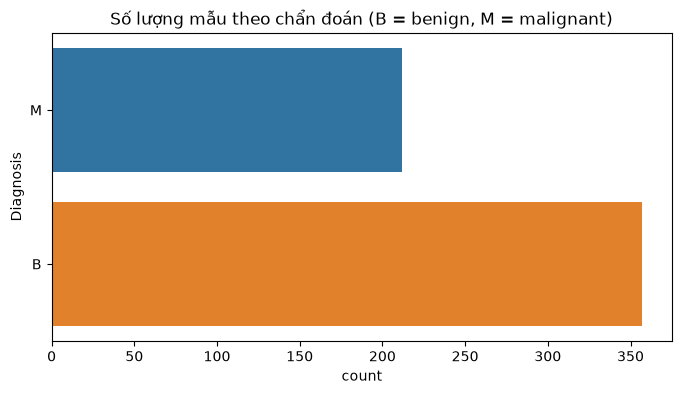

In [6]:
# Số lượng khối u lành tính (B) và ác tính (M)
print(data['Diagnosis'].value_counts())

plt.figure(figsize=(8, 4))
sns.countplot(y='Diagnosis', data=data, hue='Diagnosis')
plt.title('Số lượng mẫu theo chẩn đoán (B = benign, M = malignant)')
plt.show()

Đặng Phan Duy - 6451071010

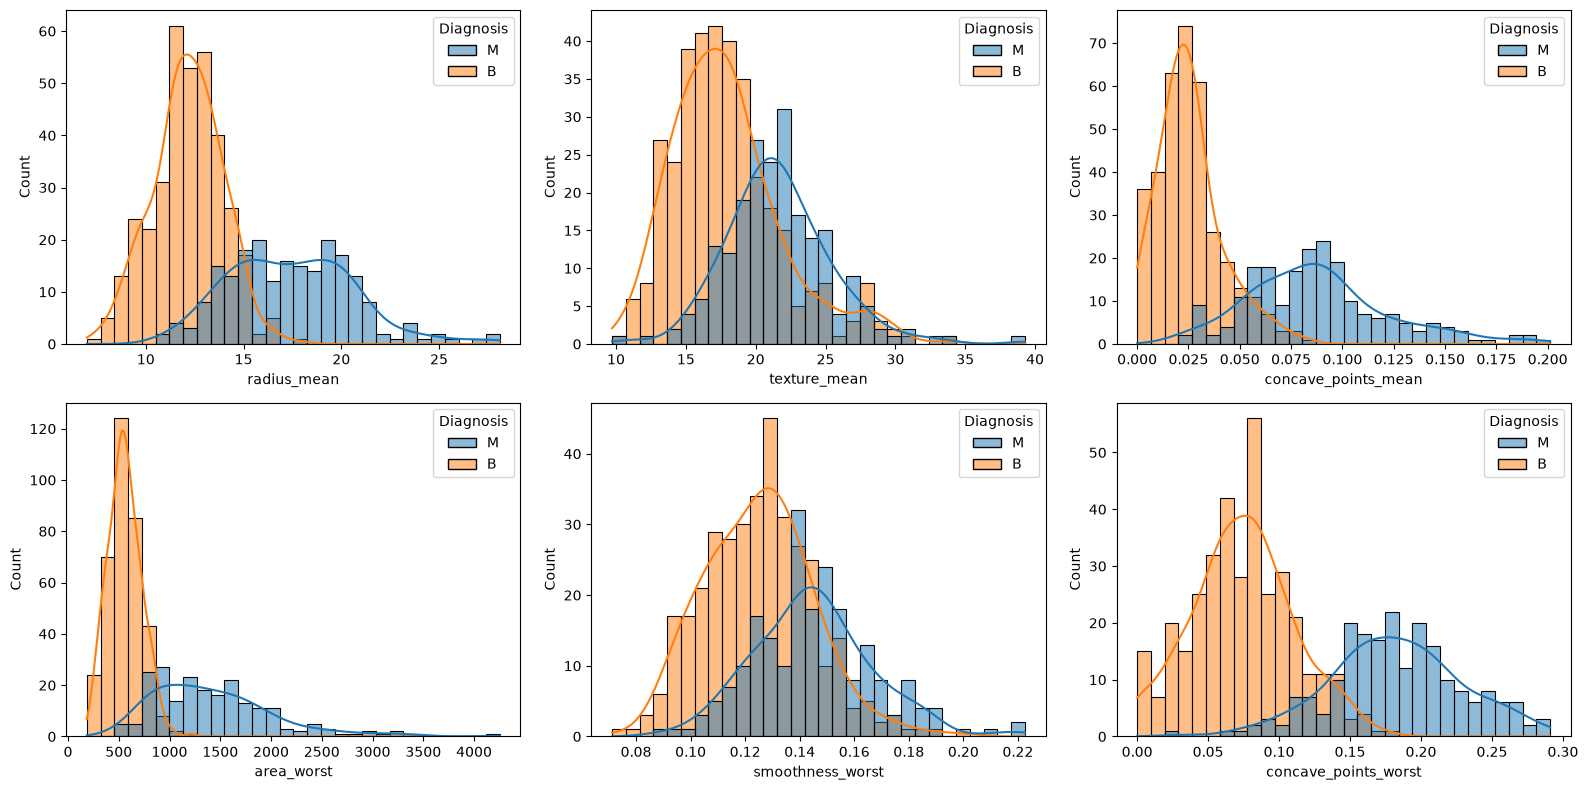

In [7]:
# Phân bố một số thuộc tính tiêu biểu theo chẩn đoán
plt.figure(figsize=(16, 8))
for i, col in enumerate(['radius_mean', 'texture_mean', 'concave_points_mean',
                         'area_worst', 'smoothness_worst', 'concave_points_worst']):
    plt.subplot(2, 3, i + 1)
    sns.histplot(data=data, x=col, hue='Diagnosis', kde=True, bins=30)
plt.tight_layout()
plt.show()

Đặng Phan Duy - 6451071010

## 3. Tiền xử lý dữ liệu

Bỏ cột ID (không mang thông tin), tách nhãn Diagnosis ra để đánh giá (M = 1, B = 0). Các thuộc tính có miền giá trị rất khác nhau (ví dụ area_worst lên đến hàng nghìn, smoothness_mean chỉ khoảng 0.1) nên cần chuẩn hóa (StandardScaler: trung bình 0, độ lệch chuẩn 1) để thuộc tính có giá trị lớn không lấn át khoảng cách Euclide.

In [8]:
X = data[feature_names].values
y = (data['Diagnosis'] == 'M').astype(int).values   # 1 = malignant, 0 = benign
target_names = ['benign', 'malignant']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("X:", X.shape, "- y:", y.shape)
print("Trước chuẩn hóa - min/max của area_worst:", X[:, feature_names.index('area_worst')].min(), "/", X[:, feature_names.index('area_worst')].max())
print("Sau chuẩn hóa - mean:", X_scaled.mean().round(4), "- std:", X_scaled.std().round(4))

X: (569, 30) - y: (569,)
Trước chuẩn hóa - min/max của area_worst: 185.2 / 4254.0
Sau chuẩn hóa - mean: -0.0 - std: 1.0


Đặng Phan Duy - 6451071010

## 4. Xác định số cụm

Bài toán cần 2 nhóm (lành tính / ác tính), nhưng vẫn khảo sát bằng phương pháp khuỷu tay và hệ số Silhouette để xem cấu trúc tự nhiên của dữ liệu.

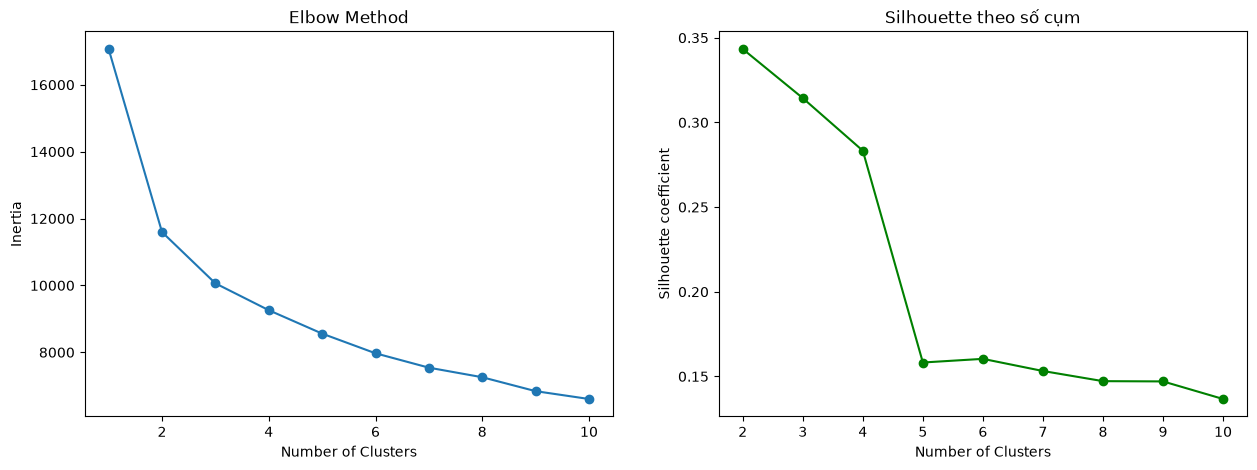

k                1           2           3          4          5          6   \
Inertia     17070.0  11595.5266  10061.7978  9258.9891  8558.6607  7970.2638   
Silhouette      NaN      0.3434      0.3144     0.2833     0.1582     0.1604   

k                  7          8          9          10  
Inertia     7540.3187  7254.3262  6837.6289  6603.4044  
Silhouette     0.1532     0.1472     0.1470     0.1367  


In [9]:
inertia, silhouette = [], []
for n in range(1, 11):
    algorithm = KMeans(n_clusters=n, n_init=10, random_state=42).fit(X_scaled)
    inertia.append(algorithm.inertia_)
    silhouette.append(metrics.silhouette_score(X_scaled, algorithm.labels_) if n > 1 else np.nan)

plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
plt.plot(np.arange(1, 11), inertia, 'o-')
plt.xlabel('Number of Clusters'), plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.subplot(1, 2, 2)
plt.plot(np.arange(1, 11), silhouette, 'o-', color='green')
plt.xlabel('Number of Clusters'), plt.ylabel('Silhouette coefficient')
plt.title('Silhouette theo số cụm')
plt.show()

print(pd.DataFrame({'k': range(1, 11), 'Inertia': inertia, 'Silhouette': silhouette}).set_index('k').T.round(4))

Đặng Phan Duy - 6451071010

Nhận xét: đường inertia giảm mạnh nhất từ k = 1 sang k = 2, sau đó giảm chậm dần (khuỷu tay tại k = 2). Hệ số Silhouette cũng cao nhất tại k = 2 (≈ 0.34) và giảm dần khi tăng k. Như vậy cấu trúc tự nhiên của dữ liệu là 2 cụm, phù hợp với 2 nhóm lành tính / ác tính, nên chọn k = 2.

## 5. Gom cụm bằng k-Means với k = 2

In [10]:
kmeans = KMeans(n_clusters=2, n_init=10, random_state=42)
clusters = kmeans.fit_predict(X_scaled)

print("Số lượng mẫu trong từng cụm:", np.bincount(clusters))
print("Silhouette coefficient:", metrics.silhouette_score(X_scaled, clusters))

Số lượng mẫu trong từng cụm: [375 194]
Silhouette coefficient: 0.34338224069077805


Đặng Phan Duy - 6451071010

In [11]:
# Tâm cụm (đưa về thang đo gốc) của một số thuộc tính
centers = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=feature_names)
centers.index.name = 'Cluster'
centers[['radius_mean', 'texture_mean', 'area_mean', 'concavity_mean', 'concave_points_mean',
         'radius_worst', 'area_worst', 'concave_points_worst']]

,radius_mean,texture_mean,area_mean,concavity_mean,concave_points_mean,radius_worst,area_worst,concave_points_worst
Cluster,,,,,,,,
0,12.426691,18.262427,486.772267,0.042679,0.026155,13.768477,596.520267,0.076508
1,17.414536,21.275258,979.857216,0.177949,0.092921,21.103041,1429.673711,0.188249


Đặng Phan Duy - 6451071010

## 6. So sánh kết quả gom cụm với chẩn đoán thực tế

In [12]:
# Bảng phân bố chẩn đoán thực tế trong từng cụm
pd.crosstab(pd.Series(clusters, name='Cluster'), data['Diagnosis'])

Diagnosis,B,M
Cluster,,
0,339,36
1,18,176


Đặng Phan Duy - 6451071010

Gán nhãn cho mỗi cụm là chẩn đoán chiếm đa số trong cụm đó (majority vote).

In [13]:
cluster_to_label = {c: np.bincount(y[clusters == c]).argmax() for c in range(2)}
for c, label in cluster_to_label.items():
    print("Cluster {0} -> {1}".format(c, target_names[label]))

pred = np.array([cluster_to_label[c] for c in clusters])
kmeans_score = metrics.accuracy_score(y, pred)
print("\nAccuracy:", kmeans_score)
print("Report:\n", metrics.classification_report(y, pred, target_names=target_names, digits=4))

Cluster 0 -> benign
Cluster 1 -> malignant

Accuracy: 0.9050966608084359
Report:
               precision    recall  f1-score   support

      benign     0.9040    0.9496    0.9262       357
   malignant     0.9072    0.8302    0.8670       212

    accuracy                         0.9051       569
   macro avg     0.9056    0.8899    0.8966       569
weighted avg     0.9052    0.9051    0.9042       569



Đặng Phan Duy - 6451071010

In [14]:
kmeans_cm = metrics.confusion_matrix(y, pred)

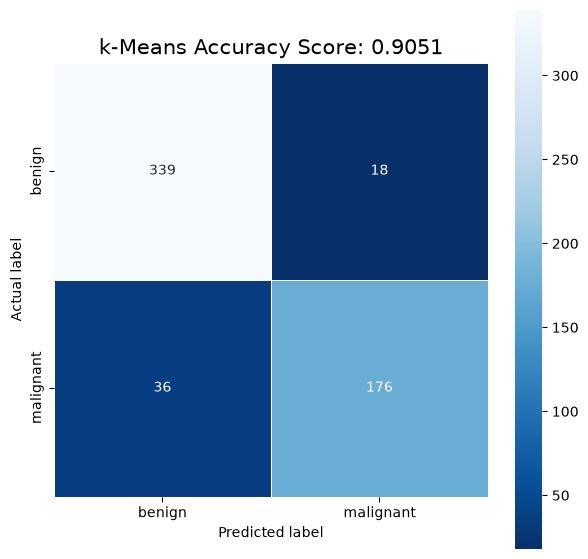

In [15]:
plt.figure(figsize=(7,7))
sns.heatmap(kmeans_cm, annot=True, fmt="d", linewidths=.5, square = True, cmap = 'Blues_r',
            xticklabels=target_names, yticklabels=target_names);
plt.ylabel('Actual label');
plt.xlabel('Predicted label');
title = 'k-Means Accuracy Score: {0:.4f}'.format(kmeans_score)
plt.title(title, size = 15);

Đặng Phan Duy - 6451071010

In [16]:
cluster_metrics = pd.DataFrame({
    'Metric': ['Homogeneity', 'Completeness', 'V-measure', 'Adjusted Rand Index', 'Normalized Mutual Information', 'Silhouette coefficient'],
    'Value': [metrics.homogeneity_score(y, clusters), metrics.completeness_score(y, clusters),
              metrics.v_measure_score(y, clusters), metrics.adjusted_rand_score(y, clusters),
              metrics.normalized_mutual_info_score(y, clusters), metrics.silhouette_score(X_scaled, clusters)]
})
cluster_metrics

,Metric,Value
0,Homogeneity,0.524888
1,Completeness,0.540147
2,V-measure,0.532408
3,Adjusted Rand Index,0.653625
4,Normalized Mutual Information,0.532408
5,Silhouette coefficient,0.343382


Đặng Phan Duy - 6451071010

## 7. Trực quan hóa kết quả gom cụm

Dữ liệu có 30 chiều nên dùng PCA để chiếu xuống 2 chiều. So sánh màu theo cụm của k-Means với màu theo chẩn đoán thực tế.

Tỷ lệ phương sai giải thích bởi 2 thành phần chính: [0.4427 0.1897] - Tổng: 0.6324


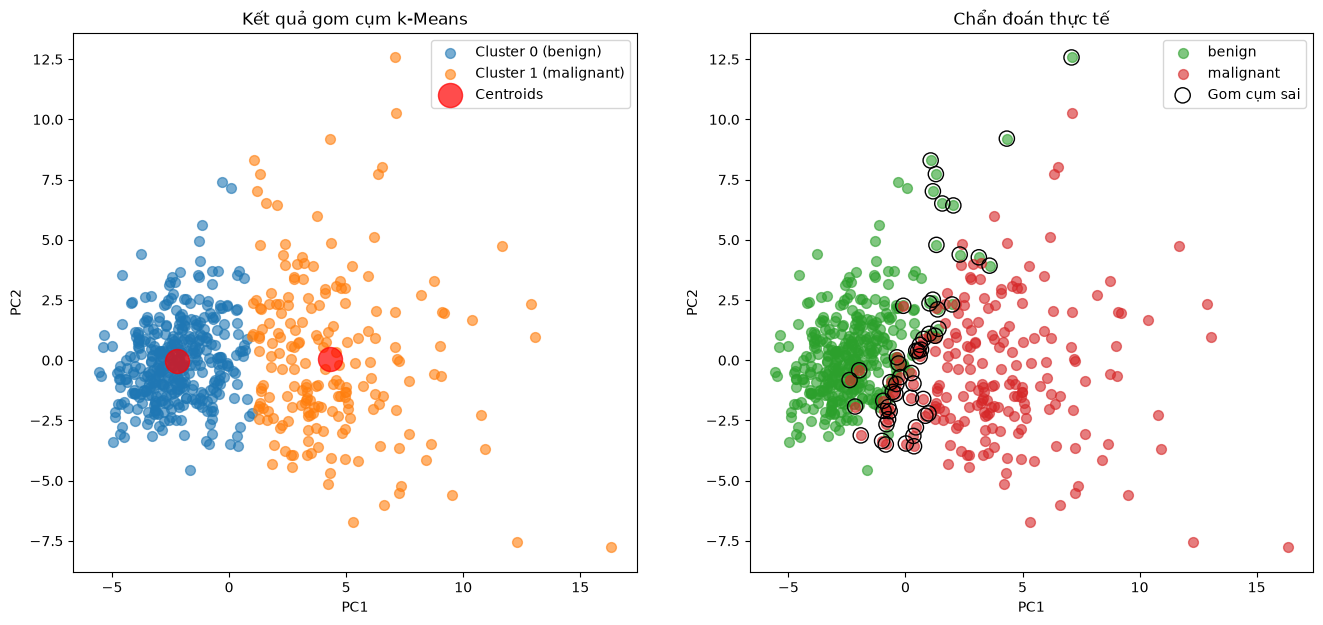

In [17]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
centers_pca = pca.transform(kmeans.cluster_centers_)
print("Tỷ lệ phương sai giải thích bởi 2 thành phần chính:", pca.explained_variance_ratio_.round(4),
      "- Tổng:", pca.explained_variance_ratio_.sum().round(4))

plt.figure(figsize=(16, 7))
plt.subplot(1, 2, 1)
for c, color in zip(range(2), ['tab:blue', 'tab:orange']):
    plt.scatter(X_pca[clusters == c, 0], X_pca[clusters == c, 1], s=50, alpha=0.6, c=color,
                label='Cluster {0} ({1})'.format(c, target_names[cluster_to_label[c]]))
plt.scatter(centers_pca[:, 0], centers_pca[:, 1], s=300, c='red', alpha=0.7, label='Centroids')
plt.xlabel('PC1'), plt.ylabel('PC2')
plt.title('Kết quả gom cụm k-Means')
plt.legend()

plt.subplot(1, 2, 2)
for label, color in zip(range(2), ['tab:green', 'tab:red']):
    plt.scatter(X_pca[y == label, 0], X_pca[y == label, 1], s=50, alpha=0.6, c=color, label=target_names[label])
wrong = pred != y
plt.scatter(X_pca[wrong, 0], X_pca[wrong, 1], s=120, facecolors='none', edgecolors='black', label='Gom cụm sai')
plt.xlabel('PC1'), plt.ylabel('PC2')
plt.title('Chẩn đoán thực tế')
plt.legend()
plt.show()

Đặng Phan Duy - 6451071010

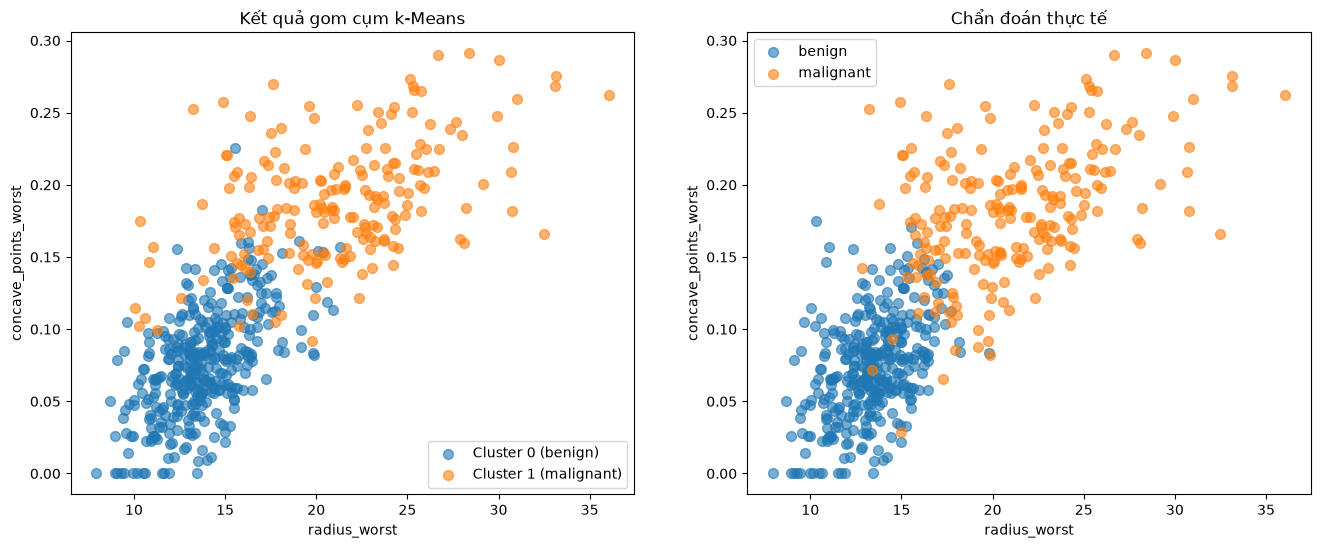

In [18]:
# Hai thuộc tính tiêu biểu: radius_worst và concave_points_worst
plt.figure(figsize=(16, 6))
for i, (labels, title, names) in enumerate([(clusters, 'Kết quả gom cụm k-Means', ['Cluster {0} ({1})'.format(c, target_names[cluster_to_label[c]]) for c in range(2)]),
                                            (y, 'Chẩn đoán thực tế', target_names)]):
    plt.subplot(1, 2, i + 1)
    for v in range(2):
        plt.scatter(data['radius_worst'][labels == v], data['concave_points_worst'][labels == v],
                    s=50, alpha=0.6, label=names[v])
    plt.xlabel('radius_worst'), plt.ylabel('concave_points_worst')
    plt.title(title)
    plt.legend()
plt.show()

Đặng Phan Duy - 6451071010

## 8. So sánh các cách gom cụm

So sánh k-Means trên dữ liệu chưa chuẩn hóa, dữ liệu đã chuẩn hóa, dữ liệu sau khi giảm chiều bằng PCA, và chỉ dùng 10 thuộc tính 'mean'.

In [19]:
def evaluate(X_in):
    c = KMeans(n_clusters=2, n_init=10, random_state=42).fit_predict(X_in)
    mapping = {k: np.bincount(y[c == k]).argmax() for k in range(2)}
    p = np.array([mapping[k] for k in c])
    return [metrics.accuracy_score(y, p),
            metrics.precision_score(y, p), metrics.recall_score(y, p), metrics.f1_score(y, p),
            metrics.adjusted_rand_score(y, c), metrics.silhouette_score(X_in, c)]

mean_idx = [feature_names.index(f'{b}_mean') for b in base]
experiments = {
    'Chưa chuẩn hóa (30 thuộc tính)': X,
    'Chuẩn hóa (30 thuộc tính)': X_scaled,
    'Chuẩn hóa + PCA 2 chiều': X_pca,
    'Chuẩn hóa (10 thuộc tính mean)': StandardScaler().fit_transform(X[:, mean_idx]),
}
compare = pd.DataFrame([[name] + evaluate(X_in) for name, X_in in experiments.items()],
                       columns=['Dữ liệu', 'Accuracy', 'Precision (M)', 'Recall (M)', 'F1 (M)', 'ARI', 'Silhouette'])
compare

,Dữ liệu,Accuracy,Precision (M),Recall (M),F1 (M),ARI,Silhouette
0,Chưa chuẩn hóa (30 thuộc tính),0.854130,0.992366,0.613208,0.758017,0.491425,0.697265
1,Chuẩn hóa (30 thuộc tính),0.905097,0.907216,0.830189,0.866995,0.653625,0.343382
2,Chuẩn hóa + PCA 2 chiều,0.906854,0.916230,0.825472,0.868486,0.659231,0.508469
3,Chuẩn hóa (10 thuộc tính mean),0.903339,0.964497,0.768868,0.855643,0.646460,0.394593


Đặng Phan Duy - 6451071010

## 9. Nhận xét

Nhận xét:

- Với dữ liệu đã chuẩn hóa và k = 2, k-Means gom được 2 cụm tương ứng khá tốt với 2 nhóm khối u: cụm 0 (375 mẫu) gồm 339 khối u lành tính, cụm 1 (194 mẫu) gồm 176 khối u ác tính. Accuracy ≈ 0.905 dù thuật toán hoàn toàn không sử dụng nhãn chẩn đoán khi gom cụm; ARI ≈ 0.65.
- Tâm cụm cho thấy cụm ác tính có nhân tế bào lớn hơn (radius, area lớn hơn) và đường viền lõm nhiều hơn (concavity, concave_points cao gấp 3 - 4 lần) so với cụm lành tính, phù hợp với đặc điểm y học của tế bào ung thư.
- Nhóm lành tính được gom tốt (Recall ≈ 0.95), còn nhóm ác tính có Recall ≈ 0.83: có 36 khối u ác tính bị gom vào cụm lành tính (sai âm tính) và 18 khối u lành tính bị gom vào cụm ác tính. Trên biểu đồ PCA, các mẫu bị gom sai nằm ở vùng giáp ranh giữa 2 nhóm, nơi các khối u ác tính có kích thước nhỏ, đặc điểm gần giống u lành tính. Trong chẩn đoán y khoa, sai âm tính là nguy hiểm nhất nên kết quả gom cụm chỉ có giá trị tham khảo, cần mô hình phân lớp có giám sát hoặc xét nghiệm bổ sung.
- Chuẩn hóa dữ liệu ảnh hưởng lớn đến kết quả: khi chưa chuẩn hóa, các thuộc tính có giá trị lớn (area_mean, area_worst lên đến hàng nghìn) chi phối khoảng cách, k-Means gần như chỉ chia theo kích thước khối u nên Recall của lớp ác tính chỉ ≈ 0.61 (Accuracy ≈ 0.85). Hệ số Silhouette khi chưa chuẩn hóa cao (≈ 0.70) nhưng chỉ phản ánh sự tách biệt theo thuộc tính area chứ không phản ánh đúng 2 nhóm chẩn đoán, nên không thể chỉ dựa vào Silhouette để đánh giá.
- Giảm chiều bằng PCA xuống 2 chiều cho kết quả tương đương 30 chiều (Accuracy ≈ 0.907, ARI ≈ 0.66) nhưng Silhouette cao hơn (≈ 0.51), cho thấy phần lớn thông tin phân biệt 2 nhóm nằm ở 2 thành phần chính đầu tiên (giải thích ≈ 63% phương sai). Chỉ dùng 10 thuộc tính mean cũng cho Accuracy ≈ 0.90, Precision của lớp ác tính cao (≈ 0.96) nhưng Recall thấp hơn (≈ 0.77).
- Kết luận: k-Means trên dữ liệu đã chuẩn hóa có thể tách khá tốt khối u lành tính và ác tính (≈ 90%), cho thấy dữ liệu có cấu trúc 2 nhóm rõ ràng; tuy nhiên vẫn kém hơn các mô hình phân lớp có giám sát (≈ 97.5% theo mô tả của bộ dữ liệu).